# TURBOLFI: Effect of the GP Tolerance Quantile

Compare TURBOLFI posteriors for **one dataset** (SA simulator, J=100, N=10k, P=10, discrepancy 5+6, sim_num=30)
when only the ABC tolerance quantile `tol` changes (`TUBOLFI/run_bolfi_mcmc_by_tol.py`).
For every `tol`, `gp_retrive(..., notes="early_stop")` refits the GP on the same stored early-stop
training points, then `MCMC_sampling` runs 4 DEMetropolisZ chains × 5,000 draws (seed 42).

**What `tol` means:** `tol = quantile_q(−discrepancy)` over *all* stored stage-2 training targets
(`est_tol` in `TuRbolfi_GPU.py`). Targets are negative discrepancies, so a **larger `tol` is a stricter
threshold** (e.g. 0.99 keeps only the closest 1% of discrepancies).

**Data source:** `results/tubolfi_results/SA/J100_P10_N10k_I0C0M0_D5+6_SIM30/MCMC_summary_early_stop_tol=*.csv`

**Analysis includes:**
- Parameter recovery: posterior mean ± 95% HDI for each tol
- t-scores by tol
- Overall statistics per tol: coverage, RMSE, MAE, interval width
- Parameter-level tables
- Convergence diagnostics: R-hat, ESS

In [11]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')   # matplotlib built-in style; seaborn package not required


def heatmap(df, ax, cmap='YlOrRd', fmt='.3f', vmin=None, vmax=None, cbar_label=None, fontsize=8):
    # Annotated heatmap with matplotlib only (replacement for seaborn.heatmap).
    vals = df.to_numpy(dtype=float)
    im = ax.imshow(vals, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')
    ax.set_xticks(range(df.shape[1]))
    ax.set_xticklabels(df.columns)
    ax.set_yticks(range(df.shape[0]))
    ax.set_yticklabels(df.index)
    ax.set_xticks(np.arange(-0.5, df.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, df.shape[0]), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.4)
    ax.grid(which='major', visible=False)
    ax.tick_params(which='minor', length=0)
    norm = im.norm
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            v = vals[i, j]
            if np.isnan(v):
                continue
            r, g, b, _ = im.cmap(norm(v))
            color = 'white' if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else 'black'
            ax.text(j, i, format(v, fmt), ha='center', va='center', fontsize=fontsize, color=color)
    cbar = ax.figure.colorbar(im, ax=ax, shrink=0.7)
    if cbar_label:
        cbar.set_label(cbar_label)
    return im
plt.rcParams['figure.figsize'] = (14, 6)
pd.set_option('display.max_rows', 200)

# Notebook lives in results/; also works if the kernel starts at the repo root.
_here = Path.cwd()
RESULTS_ROOT = _here if (_here / 'tubolfi_results').exists() else _here / 'results'
RESULT_DIR = RESULTS_ROOT / 'tubolfi_results' / 'SA' / 'J100_P10_N10k_I0C0M0_D5+6_SIM30'
PLOT_DIR = RESULTS_ROOT / 'plots'
PLOT_DIR.mkdir(exist_ok=True)
CONFIG_TAG = 'J100_N10k_P10_SIM30'

PARAM_NAMES_P10 = [
    'beta_rating', 'beta_cost', 'beta_log_dist',
    'beta_chinese', 'beta_japanese', 'beta_korean',
    'beta_indian', 'beta_french', 'beta_mexican', 'beta_lebanese',
]
TRUE_VALUES_P10 = {
    'beta_rating': 0.75, 'beta_cost': -0.40, 'beta_log_dist': -0.60,
    'beta_chinese': 0.83, 'beta_japanese': 1.25, 'beta_korean': 0.75,
    'beta_indian': 1.00, 'beta_french': 0.95, 'beta_mexican': 1.30,
    'beta_lebanese': 0.90,
}
print(f'Result folder: {RESULT_DIR}  (exists={RESULT_DIR.exists()})')

Result folder: d:\onedrive\OneDrive - National University of Singapore\1.8 LFI on MNL\TooManyAlternativesToHandle-1\results\tubolfi_results\SA\J100_P10_N10k_I0C0M0_D5+6_SIM30  (exists=True)


## 1. Load TURBOLFI Results Across tol

Each `MCMC_summary_early_stop_tol=<q>.csv` is an ArviZ summary (95% HDI) produced with tolerance quantile `q`.
Columns are renamed to a shared schema: `posterior_mean`, `posterior_sd`, `hdi_low`, `hdi_high`, `true_value`, `in_hdi`.

In [12]:
TOL_PATTERN = re.compile(r'MCMC_summary_early_stop_tol=([0-9.]+)\.csv$')

frames = []
for f in sorted(RESULT_DIR.glob('MCMC_summary_early_stop_tol=*.csv')):
    m = TOL_PATTERN.search(f.name)
    if not m:
        continue
    d = pd.read_csv(f, index_col=0)
    hdi_cols = [c for c in d.columns if c.startswith('hdi_')]
    if len(hdi_cols) != 2:
        raise ValueError(f'{f.name}: expected 2 HDI columns, found {hdi_cols}')
    lo_col, hi_col = sorted(hdi_cols, key=lambda c: float(c[4:-1]))
    d = (d.rename(columns={'mean': 'posterior_mean', 'sd': 'posterior_sd',
                           lo_col: 'hdi_low', hi_col: 'hdi_high',
                           'true': 'true_value', 'covered': 'in_hdi'})
          .rename_axis('parameter').reset_index())
    d['tol'] = float(m.group(1))
    d['hdi_level'] = f'{lo_col[4:]}-{hi_col[4:]}'
    frames.append(d)

if not frames:
    raise FileNotFoundError(f'No MCMC_summary_early_stop_tol=*.csv found in {RESULT_DIR}')

df_tol = pd.concat(frames, ignore_index=True)
df_tol = df_tol[df_tol['parameter'].isin(PARAM_NAMES_P10)].copy()
df_tol['true_value'] = df_tol['parameter'].map(TRUE_VALUES_P10)
df_tol['in_hdi'] = (df_tol['true_value'] >= df_tol['hdi_low']) & (df_tol['true_value'] <= df_tol['hdi_high'])
df_tol['interval_width'] = df_tol['hdi_high'] - df_tol['hdi_low']
df_tol['signed_error'] = df_tol['posterior_mean'] - df_tol['true_value']
df_tol['abs_error'] = df_tol['signed_error'].abs()
df_tol['sq_error'] = df_tol['signed_error'] ** 2
df_tol['abs_rel_error_pct'] = df_tol['abs_error'] / df_tol['true_value'].abs() * 100
df_tol['relative_width'] = df_tol['interval_width'] / df_tol['true_value'].abs()
df_tol['t_score'] = df_tol['signed_error'] / df_tol['posterior_sd']

TOLS = sorted(df_tol['tol'].unique())
TOL_LABELS = {t: f'tol={t:g}' for t in TOLS}
tol_cmap = plt.colormaps['viridis']
TOL_COLORS = {t: tol_cmap(x) for t, x in zip(TOLS, np.linspace(0.05, 0.9, len(TOLS)))}

print(f'Loaded {len(df_tol)} rows: {len(TOLS)} tol values x {df_tol["parameter"].nunique()} parameters')
print('tol values:', TOLS)
print('HDI levels:', df_tol['hdi_level'].unique())

Loaded 60 rows: 6 tol values x 10 parameters
tol values: [np.float64(0.8), np.float64(0.85), np.float64(0.9), np.float64(0.95), np.float64(0.975), np.float64(0.99)]
HDI levels: ['2.5%-97.5%']


## 2. Parameter Recovery — Posterior Mean ± 95% HDI by tol

One row per parameter; the markers within a row are the tol values (viridis: dark purple = smallest tol → yellow = largest tol). The red tick is the true value.

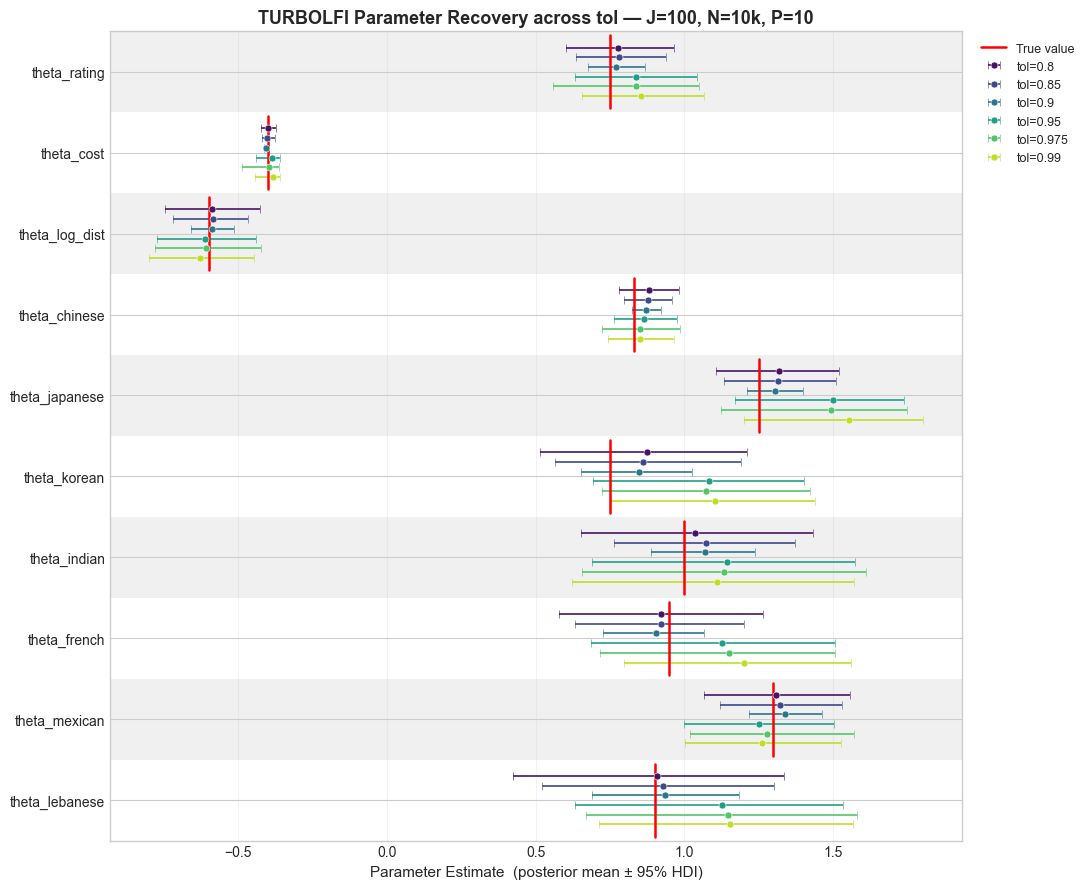

In [13]:
y_pos = {p: i for i, p in enumerate(PARAM_NAMES_P10)}
offsets = np.linspace(-0.3, 0.3, len(TOLS))

fig, ax = plt.subplots(figsize=(11, 9))
for pi in range(len(PARAM_NAMES_P10)):
    if pi % 2 == 0:
        ax.axhspan(pi - 0.5, pi + 0.5, color='#f0f0f0', zorder=0, linewidth=0)

for k, tol in enumerate(TOLS):
    d = df_tol[df_tol['tol'] == tol]
    for i, (_, row) in enumerate(d.iterrows()):
        ax.errorbar(row['posterior_mean'], y_pos[row['parameter']] + offsets[k],
                    xerr=[[row['posterior_mean'] - row['hdi_low']], [row['hdi_high'] - row['posterior_mean']]],
                    fmt='o', color=TOL_COLORS[tol], markersize=5, capsize=3, linewidth=1.2,
                    markeredgecolor='white', markeredgewidth=0.4,
                    label=TOL_LABELS[tol] if i == 0 else '_nolegend_')

for p, tv in TRUE_VALUES_P10.items():
    ax.plot([tv, tv], [y_pos[p] - 0.45, y_pos[p] + 0.45], color='red', linewidth=1.8,
            label='True value' if p == PARAM_NAMES_P10[0] else '_nolegend_')

ax.set_yticks(range(len(PARAM_NAMES_P10)))
ax.set_yticklabels([p.replace('beta_', 'theta_') for p in PARAM_NAMES_P10], fontsize=10)
ax.set_ylim(len(PARAM_NAMES_P10) - 0.5, -0.5)
ax.set_xlabel('Parameter Estimate  (posterior mean ± 95% HDI)', fontsize=11)
ax.set_title('TURBOLFI Parameter Recovery across tol — J=100, N=10k, P=10', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
ax.grid(alpha=0.25, axis='x')
plt.tight_layout()
plt.savefig(PLOT_DIR / f'turbolfi_tol_forest_{CONFIG_TAG}.png', dpi=300, bbox_inches='tight')
plt.show()

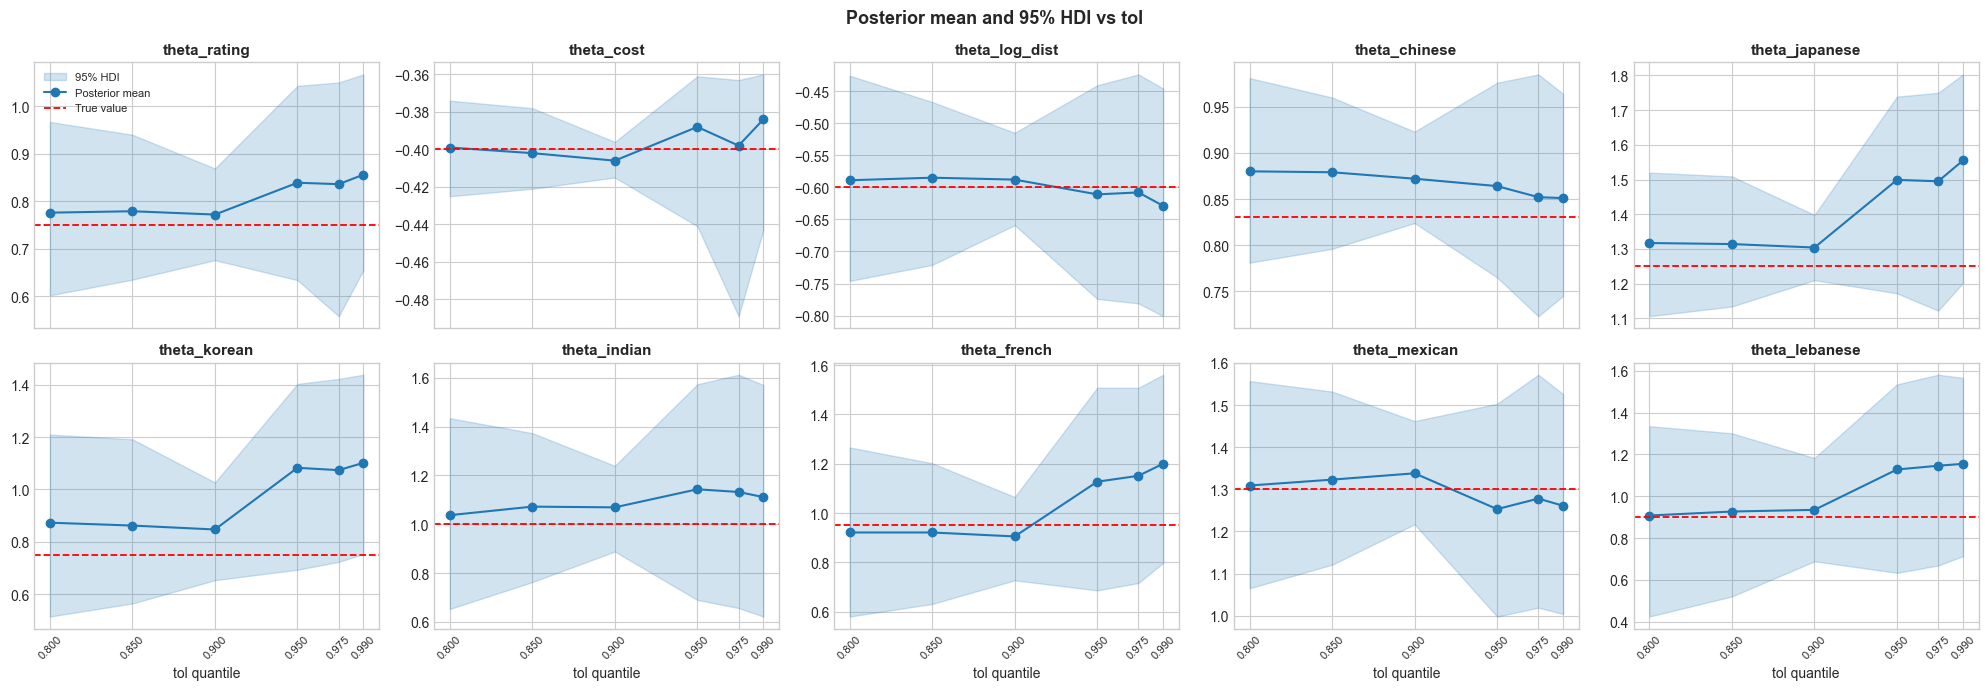

In [14]:
# ── Small multiples: one panel per parameter, x = tol ──────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
for ax, p in zip(axes.ravel(), PARAM_NAMES_P10):
    d = df_tol[df_tol['parameter'] == p].sort_values('tol')
    ax.fill_between(d['tol'], d['hdi_low'], d['hdi_high'], color='C0', alpha=0.2, label='95% HDI')
    ax.plot(d['tol'], d['posterior_mean'], 'o-', color='C0', label='Posterior mean')
    ax.axhline(TRUE_VALUES_P10[p], color='red', linestyle='--', linewidth=1.3, label='True value')
    ax.set_title(p.replace('beta_', 'theta_'), fontsize=11, fontweight='bold')
    ax.set_xticks(TOLS)
    ax.tick_params(axis='x', rotation=45, labelsize=8)
for ax in axes[1]:
    ax.set_xlabel('tol quantile')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Posterior mean and 95% HDI vs tol', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(PLOT_DIR / f'turbolfi_tol_per_param_{CONFIG_TAG}.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# ── Posterior mean / HDI tables (parameter x tol) ──────────────────────────────
def tol_pivot(metric):
    piv = df_tol.pivot(index='parameter', columns='tol', values=metric).reindex(PARAM_NAMES_P10)
    piv.columns = [TOL_LABELS[c] for c in piv.columns]
    return piv

true_col = pd.Series(TRUE_VALUES_P10, name='true').reindex(PARAM_NAMES_P10)
print('POSTERIOR MEAN')
display(pd.concat([true_col, tol_pivot('posterior_mean')], axis=1).style.format('{:.4f}'))
print('95% HDI LOW')
display(tol_pivot('hdi_low').style.format('{:.4f}'))
print('95% HDI HIGH')
display(tol_pivot('hdi_high').style.format('{:.4f}'))
print('95% HDI WIDTH')
display(tol_pivot('interval_width').style.format('{:.4f}').background_gradient(cmap='YlOrRd', axis=None))

## 3. T-score by tol

$t = (\hat{\mu} - \theta_{\text{true}})/\hat{\sigma}$, with $\hat\sigma$ the posterior SD.
$|t|<1.645$ good, $1.645$–$1.96$ marginal, $>1.96$ significant bias.

In [ ]:
fig, ax = plt.subplots(figsize=(12, max(5, len(TOLS) * 0.7 + 2)))
param_markers = ['o', 's', 'D', '^', 'v', '<', '>', 'P', 'X', '*']
rng = np.linspace(-0.25, 0.25, len(PARAM_NAMES_P10))
for j, p in enumerate(PARAM_NAMES_P10):
    d = df_tol[df_tol['parameter'] == p]
    ax.scatter(d['t_score'], [TOLS.index(t) + rng[j] for t in d['tol']],
               marker=param_markers[j], s=55, alpha=0.75, color=f'C{j}',
               edgecolors='white', linewidths=0.35, label=p.replace('beta_', 'theta_'))

ax.axvspan(-1.645, 1.645, alpha=0.09, color='green', zorder=0)
ax.axvspan(-1.96, -1.645, alpha=0.05, color='orange', zorder=0)
ax.axvspan(1.645, 1.96, alpha=0.05, color='orange', zorder=0)
ax.axvline(0, color='green', linewidth=1.8, alpha=0.9, label='t = 0 (unbiased)')
for s in (-1, 1):
    ax.axvline(s * 1.645, color='gray', linestyle=':', linewidth=1.2, label='±1.645 (90%)' if s > 0 else '_nolegend_')
    ax.axvline(s * 1.96, color='orange', linestyle='--', linewidth=1.8, label='±1.96 (95%)' if s > 0 else '_nolegend_')

ax.set_yticks(range(len(TOLS)))
ax.set_yticklabels([TOL_LABELS[t] for t in TOLS])
ax.invert_yaxis()
ax.set_xlabel(r't-score  $=(\hat{\mu} - \theta_{\rm true})/\hat{\sigma}$', fontsize=12)
ax.set_ylabel('Tolerance quantile', fontsize=12)
ax.set_title('TURBOLFI T-scores by tol — J=100, N=10k, P=10', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(PLOT_DIR / f'turbolfi_tol_t_score_{CONFIG_TAG}.png', dpi=300, bbox_inches='tight')
plt.show()

display(tol_pivot('t_score').style.format('{:.2f}').background_gradient(cmap='RdBu_r', vmin=-3, vmax=3, axis=None))

## 4. Overall Statistics per tol

Aggregate over the P=10 parameters for each tol:
- **Coverage** — % of parameters with the true value inside the 95% HDI
- **RMSE / MAE** — errors of posterior means
- **Mean HDI width** and **mean relative width**
- **max |t|**

In [15]:
agg_tol = df_tol.groupby('tol').agg(
    coverage_pct   = ('in_hdi',            lambda x: x.mean() * 100),
    rmse           = ('sq_error',          lambda x: np.sqrt(x.mean())),
    mae            = ('abs_error',         'mean'),
    max_abs_error  = ('abs_error',         'max'),
    mean_rel_err   = ('abs_rel_error_pct', 'mean'),
    mean_width     = ('interval_width',    'mean'),
    mean_rel_width = ('relative_width',    'mean'),
    max_abs_t      = ('t_score',           lambda x: x.abs().max()),
    max_rhat       = ('r_hat',             'max'),
    min_ess_bulk   = ('ess_bulk',          'min'),
).reset_index()

lower_better = ['rmse', 'mae', 'max_abs_error', 'mean_rel_err', 'max_abs_t', 'max_rhat']
display(
    agg_tol.style
    .format({'tol': '{:g}', 'coverage_pct': '{:.1f}', 'rmse': '{:.4f}', 'mae': '{:.4f}',
             'max_abs_error': '{:.4f}', 'mean_rel_err': '{:.2f}', 'mean_width': '{:.4f}',
             'mean_rel_width': '{:.3f}', 'max_abs_t': '{:.2f}', 'max_rhat': '{:.3f}',
             'min_ess_bulk': '{:.0f}'})
    .highlight_min(subset=lower_better, color='#c8f7c5')
    .highlight_max(subset=['coverage_pct', 'min_ess_bulk'], color='#c8f7c5')
)

,tol,coverage_pct,rmse,mae,max_abs_error,mean_rel_err,mean_width,mean_rel_width,max_abs_t,max_rhat,min_ess_bulk
0,0.8,100.0,0.0503,0.0361,0.1230,4.17,0.4915,0.554,0.96,1.010,456
1,0.85,100.0,0.0523,0.0422,0.1120,4.78,0.4141,0.467,1.14,1.010,657
2,0.9,100.0,0.0492,0.0420,0.0970,4.72,0.2445,0.276,1.62,1.010,615
3,0.95,100.0,0.1698,0.1323,0.3330,14.70,0.5422,0.609,1.84,1.020,328
4,0.975,100.0,0.1708,0.1288,0.3240,14.21,0.5777,0.654,1.76,1.140,21
5,0.99,90.0,0.1926,0.1484,0.3520,16.56,0.5441,0.611,2.10,1.030,141


In [ ]:
# ── Metrics vs tol ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (col, title) in zip(axes, [('coverage_pct', 'Coverage (%)'), ('rmse', 'RMSE'),
                                   ('mean_width', 'Mean 95% HDI width'), ('max_abs_t', 'max |t|')]):
    ax.plot(agg_tol['tol'], agg_tol[col], 'o-', color='C1', linewidth=1.8)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('tol quantile')
    ax.set_xticks(TOLS)
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylim(0, 105)
axes[3].axhline(1.96, color='orange', linestyle='--', linewidth=1.2)
fig.suptitle('TURBOLFI summary metrics vs tol — J=100, N=10k, P=10', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(PLOT_DIR / f'turbolfi_tol_metrics_{CONFIG_TAG}.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Parameter-Level Detail (parameter × tol)

In [ ]:
print('── Absolute error |posterior_mean − true| ──')
display(tol_pivot('abs_error').style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', axis=None))

print('── Relative error (%) ──')
display(tol_pivot('abs_rel_error_pct').style.format('{:.2f}').background_gradient(cmap='RdYlGn_r', axis=None))

print('── Signed error ──')
display(tol_pivot('signed_error').style.format('{:.4f}').background_gradient(cmap='RdBu', axis=None))

print('── Relative HDI width ──')
display(tol_pivot('relative_width').style.format('{:.4f}').background_gradient(cmap='YlOrRd', axis=None))

print('── True value inside 95% HDI ──')
cov_piv = tol_pivot('in_hdi')
display(cov_piv.style
        .format(lambda v: '✓' if v else '✗')
        .map(lambda v: 'background-color: #c8f7c5' if v else 'background-color: #f7c5c5'))

In [ ]:
# ── Heatmaps: parameter × tol ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
for ax, (metric, title, cmap, fmt) in zip(axes, [
    ('abs_error',         'Absolute Error',     'YlOrRd', '.3f'),
    ('abs_rel_error_pct', 'Relative Error (%)', 'YlOrRd', '.1f'),
    ('relative_width',    'Relative HDI Width', 'YlOrBr', '.3f'),
]):
    piv = tol_pivot(metric)
    piv.index = [p.replace('beta_', '') for p in piv.index]
    heatmap(piv, ax=ax, cmap=cmap, fmt=fmt, cbar_label=title)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('tol')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
fig.suptitle('Parameter × tol', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Convergence Diagnostics per tol

- R-hat < 1.01 excellent; < 1.05 acceptable
- ESS > 400 sufficient

In [ ]:
conv = df_tol.groupby('tol').agg(
    max_rhat      = ('r_hat',    'max'),
    mean_rhat     = ('r_hat',    'mean'),
    min_ess_bulk  = ('ess_bulk', 'min'),
    mean_ess_bulk = ('ess_bulk', 'mean'),
    min_ess_tail  = ('ess_tail', 'min'),
).reset_index()
conv['converged'] = (conv['max_rhat'] < 1.05) & (conv['min_ess_bulk'] > 400) & (conv['min_ess_tail'] > 400)
display(conv.round({'max_rhat': 3, 'mean_rhat': 3, 'min_ess_bulk': 0, 'mean_ess_bulk': 0, 'min_ess_tail': 0}))
print(f"Converged: {conv['converged'].sum()}/{len(conv)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
heatmap(tol_pivot('r_hat'), ax=axes[0], cmap='YlOrRd', fmt='.2f', vmin=1.0, vmax=1.05)
axes[0].set_title('R-hat (parameter × tol)', fontweight='bold')
heatmap(tol_pivot('ess_bulk'), ax=axes[1], cmap='YlGn', fmt='.0f')
axes[1].set_title('Bulk ESS (parameter × tol)', fontweight='bold')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()